#### Import Libraries
Import python libraries that will be utilized in the notebook for data import and analysis.

In [2]:
#### Importing Required Libraries
#import the libraries needed for data handling and visualization.
import pandas as pd
import matplotlib.pyplot as plt
import math 
%matplotlib inline
import seaborn as sns
import numpy as np
import os
import shutil
import re
import csv
from Bio import Entrez 
from Bio import SeqIO
from Bio import Medline
from bioservices import KEGG
from bioservices import UniProt
from Bio.KEGG.REST import kegg_get
from Bio.KEGG.KGML import KGML_parser
from Bio.Graphics.KGML_vis import KGMLCanvas
from Bio.Graphics.ColorSpiral import ColorSpiral
from IPython.display import Image, HTML
from IPython.display import Image, IFrame, display, HTML


#### Parse the actionability file based on your search term and create a new file that contains the following columns:  GENE, MUTATION_REMARK, DISEASE, ACTIONABILITY_RANK, DEVELOPMENT_STATUS, DRUG_COMBINATION,  PRIMARY_OUTCOME_MEASURE, TRIAL_STATUS, and PATIENT_PRESCREENING.

Goal: Filter a TSV file for specific criteria (e.g., gene name, disease keywords) and export columns to a new CSV file.

In [4]:
#Load the actionability dataset (from COSMIC)
cosmic_data = pd.read_csv("Actionability_AllData_v14_GRCh37.tsv", sep="\t", low_memory=False)
from IPython.display import FileLink
FileLink("Actionability_AllData_v14_GRCh37.tsv")

#Filter by specific genes (e.g., EGFR and FGFR1)
selected_records = cosmic_data[cosmic_data["GENE"].isin(["EGFR", "FGFR1"])]

#Further filter by disease keywords: 'lung / carcinoma / non small cell carcinoma'
selected_records = selected_records[
    selected_records["DISEASE"].str.contains("lung / carcinoma / non small cell carcinoma")
]

#Narrow the columns to the ones of interest
filtered_nsclc_data = selected_records[
    [
        "GENE",
        "MUTATION_REMARK",
        "DISEASE",
        "ACTIONABILITY_RANK",
        "DEVELOPMENT_STATUS",
        "DRUG_COMBINATION",
        "PRIMARY_OUTCOME_MEASURE",
        "TRIAL_STATUS",
        "PATIENT_PRESCREENING"
    ]
]

#Export the filtered data to a CSV file without row indices
filtered_nsclc_data.to_csv("NSCLC_Actionability_Overview.csv", index=False)
from IPython.display import FileLink
FileLink("NSCLC_Actionability_Overview.csv")


/Users/amycui/Documents/Documents_Amy/Bioinformatics_Masters/Final/NSCLC_Actionability_Overview.csv

### Explanation

selected_records extracts rows matching the genes of interest.
Rows are further constrained to those with “lung / carcinoma / non small cell carcinoma.”
We choose specific columns for clarity.
The final DataFrame is written to NSCLC_Actionability_Overview.csv.

#### Create a scatter plot based on the gene and mutation_remark compared to the Patient_Prescreening based on whether Expression confirmed or not.
Goal: Visualize how MUTATION_REMARK and GENE relate to PATIENT_PRESCREENING.


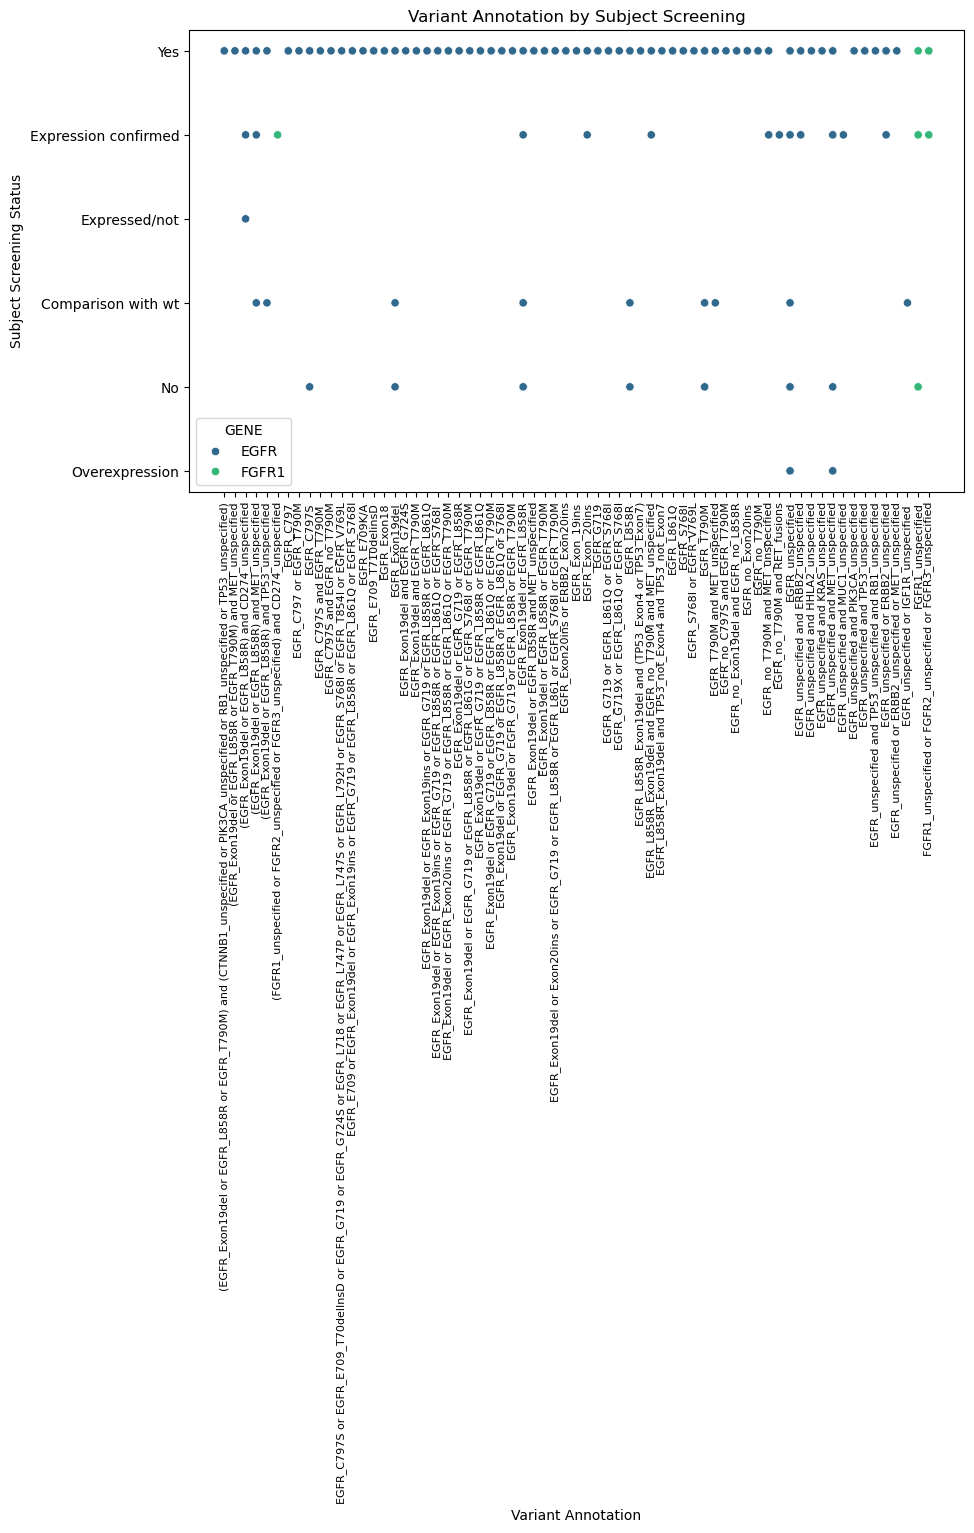

In [7]:
#Initialize the figure
plt.figure(figsize=(10, 6))

#Use seaborn to create a scatter plot
sns.scatterplot(
    data=filtered_nsclc_data,
    x="MUTATION_REMARK",
    y="PATIENT_PRESCREENING",
    hue="GENE",
    palette="viridis"
)

#Add plot title, axes labels, and rotate x-axis labels
plt.title("Variant Annotation by Subject Screening")
plt.xlabel("Variant Annotation")
plt.ylabel("Subject Screening Status")
plt.xticks(rotation=90, fontsize=8)

#Save the figure and display
plt.savefig("Variant_Annotation_vs_Screening.pdf")
plt.show()

display(HTML("<b>Scatter Plot PDF:</b>"))
display(IFrame("Variant_Annotation_vs_Screening.pdf", width=600, height=500))

### Explanation
plt.figure() sets the plot size.
sns.scatterplot() conveniently maps columns from the DataFrame to plot aesthetics without manual grouping.
The figure is saved as Variant_Annotation_vs_Screening.pdf.

#### Create a bar chart based on the actionability_rank and DRUG_COMBINATION, which is the treatment.  The x-axis would be the actionability_ranks and the y-axis would be the drug combinations.
Goal: Count the number of drug combinations per actionability rank and plot as a bar chart.

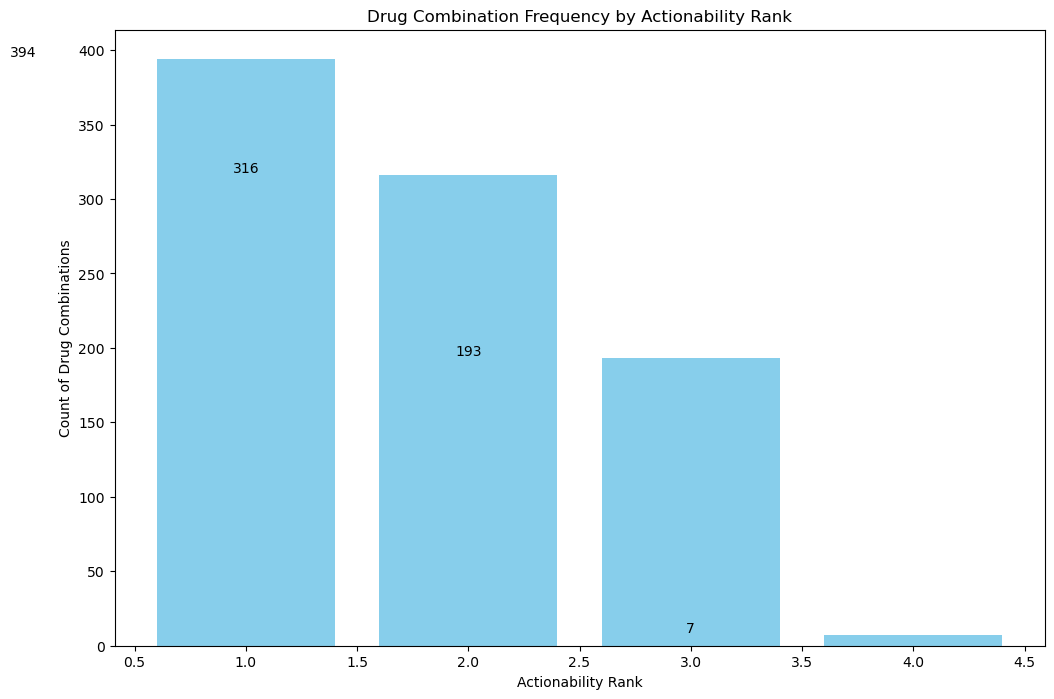

In [10]:
#Group by ACTIONABILITY_RANK to count how many drug combinations appear per rank
treatment_counts = filtered_nsclc_data.groupby("ACTIONABILITY_RANK")["DRUG_COMBINATION"].count()
x_vals = treatment_counts.index
y_vals = treatment_counts.values

#Initialize the figure
plt.figure(figsize=(12, 8))

#Plot the bar chart
plt.bar(x_vals, y_vals, color='skyblue')

#Place labels on the bars
def label_bars(x_data, y_data):
    for i in range(len(x_data)):
        plt.text(i, y_data[i], str(y_data[i]), ha='center', va='bottom')

#Call the label function
label_bars(x_vals, y_vals)

plt.title("Drug Combination Frequency by Actionability Rank")
plt.xlabel("Actionability Rank")
plt.ylabel("Count of Drug Combinations")
plt.savefig("DrugCombo_by_Rank.pdf")
plt.show()


### Explanation
We use .groupby() on ACTIONABILITY_RANK to count the frequency of DRUG_COMBINATION.
The label_bars function adds text labels above each bar.
The final chart is saved as DrugCombo_by_Rank.pdf.

#### Create a BioPython session. Use entrez to search the protein and pubmed databases, return a max of 100 based on your search term. Capture the IDs, then perform and fetch the fasta sequences and articles and return them to a file on your local machine. Create a histogram based on the length of the fasta sequences. 

Goal:

Retrieve protein FASTA sequences associated with NSCLC and cisplatin from NCBI.
Retrieve up to 100 PubMed articles matching the same terms, then parse them into a DataFrame.

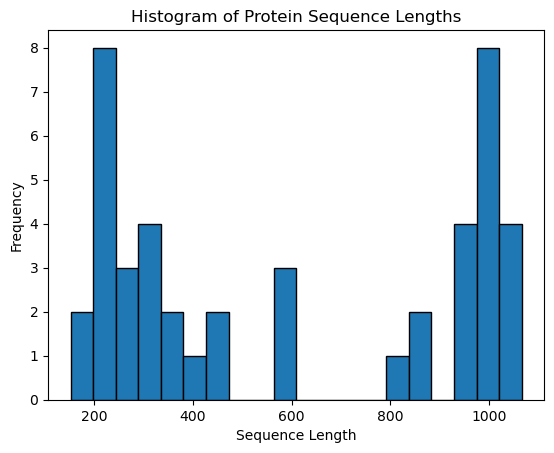

/Users/amycui/Documents/Documents_Amy/Bioinformatics_Masters/Final/Cisplatin_NSCLC_PubMed.csv

In [13]:
Entrez.email = "amycui2@yahoo.com"  # Required by NCBI

#Entrez search for protein sequences
protein_handle = Entrez.esearch(db="protein", retmax=100, term="NSCLC and cisplatin")
protein_result = Entrez.read(protein_handle)
protein_ids = protein_result["IdList"]

#fetch FASTA sequences and write to file
protein_fasta_fetch = Entrez.efetch(db="protein", id=protein_ids, rettype="fasta", retmode="text")
fasta_content = protein_fasta_fetch.read()

with open("nsclc_cisplatin_sequences.fa", "w") as outfile:
    outfile.write(fasta_content)

#build a dictionary and plot histogram of sequence lengths
fasta_dict = {}
for seq_record in SeqIO.parse("nsclc_cisplatin_sequences.fa", "fasta"):
    fasta_dict[seq_record.id] = str(seq_record.seq)

seq_lens = [len(seq) for seq in fasta_dict.values()]

plt.hist(seq_lens, bins=20, edgecolor='black')
plt.title("Histogram of Protein Sequence Lengths")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.savefig("SequenceLength_Distribution.pdf")
plt.show()

display(HTML("<b>Histogram PDF:</b>"))
display(IFrame("SequenceLength_Distribution.pdf", width=600, height=500))

#Entrez search for PubMed articles
pubmed_handle = Entrez.esearch(db="pubmed", retmax=100, term="NSCLC AND Cisplatin")
pubmed_record = Entrez.read(pubmed_handle)
pubmed_id_list = ",".join(pubmed_record["IdList"])

#Fetch the articles in Medline format
pubmed_fetch = Entrez.efetch(db="pubmed", id=pubmed_id_list, rettype="medline", retmode="text")
pub_record_list = list(Medline.parse(pubmed_fetch))

pubmed_entries = []
for entry in pub_record_list:
    pubmed_entries.append({
        "PMID": entry.get("PMID", "N/A"),
        "Accession": entry.get("PMID", "N/A"),
        "PublicationDate": entry.get("DP", "N/A"),
        "JournalTitle": entry.get("JT", "N/A"),
        "ArticleTitle": entry.get("TI", "N/A"),
        "Authors": ", ".join(entry.get("AU", ["N/A"])),
        "Abstract": entry.get("AB", "N/A")
    })

pubmed_df = pd.DataFrame(pubmed_entries)
pubmed_df.to_csv("Cisplatin_NSCLC_PubMed.csv", index=False, encoding="utf-8")
pubmed_df
from IPython.display import FileLink
FileLink("Cisplatin_NSCLC_PubMed.csv")

### Explanation
Entrez ESearch for the keyword “NSCLC and cisplatin” in the protein database.
EFetch the FASTA sequences, save them to nsclc_cisplatin_sequences.fa, then parse to plot a histogram of sequence lengths.
Repeat with the pubmed database: retrieve 100 article IDs, fetch them in Medline format, parse into a DataFrame, and finally save to Cisplatin_NSCLC_PubMed.csv.

### Create a Bioservices KEGG session. Use the find method and pass in the parameters 'disease' and your search term.  Capture the output based on the ID, ex. 'H01692'. Write the output to a file. 1pt. Obtain the 'hsa' number, ex. 'hsa04150', and create the pathway map,1pt. Obtain the network annotation and write that a file,1pt.
Goal:

Use bioservices KEGG to query a disease term (e.g., Non Small Cell Lung Cancer), retrieve the relevant disease identifier (ds), and then fetch associated database information.
Identify the KEGG pathway (hsa code) and render the pathway map image.

In [16]:
kegg_svc = KEGG(verbose=False)

#Find disease info for Non Small Cell Lung Cancer
disease_search = kegg_svc.find("disease", "Non Small Cell Lung Cancer")
disease_entries = disease_search.split("\t")
disease_id = disease_entries[0][3:]  # e.g. "H01692"

#Get detailed disease info
disease_detail = kegg_svc.get(disease_id)

#Write to file
with open("NSCLC_Disease_DB.txt", "w") as nsclc_out:
    nsclc_out.write(f"Search Results:\n{disease_search}\n\nDetailed Info:\n{disease_detail}")
from IPython.display import FileLink
FileLink("NSCLC_Disease_DB.txt")

#Find the pathway ID
path_search = kegg_svc.find("pathway", "Non Small Cell Lung Cancer")
path_lines = path_search.split("\t")
path_suffix = path_lines[0][8:]
path_code = "hsa" + path_suffix  # e.g. "hsa04150"

#Retrieve pathway image
img = Image(kegg_get(path_code, "image").read())
img

#Parse and save the pathway map as PDF
pathway_obj = KGML_parser.read(kegg_get(path_code, "kgml"))
canvas_obj = KGMLCanvas(pathway_obj)
canvas_obj.import_imagemap = True
canvas_obj.draw("NSCLC_Pathway_Map.pdf")
from IPython.display import FileLink
FileLink("NSCLC_Pathway_Map.pdf")


/Users/amycui/Documents/Documents_Amy/Bioinformatics_Masters/Final/NSCLC_Pathway_Map.pdf

### Explanation
Use kegg_svc.find("disease", "Non Small Cell Lung Cancer") to locate the disease entry.
Extract the ID and fetch details.
Similarly, do a .find("pathway", ...) call, extract the pathway code, and retrieve the KGML or map image.
KGMLCanvas converts the KGML data into a visual PDF file.

### Create Bioservices UniProt object that uses the search method to perform a query. Ex. result = u.search("protein_name:human NameOfProtein protein AND organism_name:human, go(biological process)", frmt="tsv"),1pt. Create a dataframe for it within your notebook,1pt.
Goal:

Query UniProt for specific terms (e.g., biological processes in EGFR) and diseases.
Convert the TSV response into a DataFrame.

In [19]:
uniprot_svc = UniProt(verbose=False)

#6a) Query for a protein and a biological process in humans
query_a = "protein_name:EGFR AND organism_name:human, go(biological process)"
result_a = uniprot_svc.search(query_a, frmt="tsv")

#Convert to DataFrame using bioservices built-in
egfr_data_a = uniprot_svc.get_df(query_a)
egfr_data_a = egfr_data_a.dropna(axis=1)
egfr_data_a.to_csv("EGFR_BiologicalProcess.csv", index=False, encoding="utf-8")
egfr_data_a

#6b) Query for a protein family and disease context
uniprot_svc2 = UniProt(verbose=False)
query_b = "family:'EGF' AND cc_disease:lung"
result_b = uniprot_svc2.search(query_b, frmt="tsv")

#Convert to DataFrame
egfr_data_b = uniprot_svc2.get_df(query_b)
egfr_data_b = egfr_data_b.dropna(axis=1)
egfr_data_b.to_csv("EGFR_Family_Lung.csv", index=False, encoding="utf-8")
egfr_data_b

from IPython.display import FileLink
FileLink("EGFR_Family_Lung.csv")


/Users/amycui/Documents/Documents_Amy/Bioinformatics_Masters/Final/EGFR_Family_Lung.csv

### Explanation

UniProt.search(...) returns results in TSV format.
We can use get_df(...) to directly get a pandas DataFrame.
We drop columns with too many NaN values using .dropna(axis=1).
The DataFrame is exported to CSV files for further usage.

### Create a function that defines an object, via bioservices or biopython, that will run a query and return a file of fasta sequences using the search term assigned to you. All sequences must be human.
Goal:

Define a function that takes an email and a search term, then queries the protein database for Homo sapiens sequences matching that term.
python
Perform a BioPython Search using the term 'Gefitinib', 1pt. 

In [ ]:
def gather_fasta_records(contact_email, search_text):
    Entrez.email = contact_email
    query_handle = Entrez.esearch(db="protein", retmax=100, term=f"{search_text} AND Homo sapiens")
    query_output = Entrez.read(query_handle)
    seq_ids = query_output["IdList"]

    # Fetch the FASTA sequences
    fasta_retrieval = Entrez.efetch(db="protein", id=seq_ids, rettype="fasta", retmode="text")
    collected_lines = fasta_retrieval.read()

    # Write to file named after the search_text
    file_name = f"{search_text}.fa"
    with open(file_name, "w") as f_handle:
        f_handle.write(collected_lines)

#gather user input
my_email = input("Enter your email address: ")
my_term = input("Enter your protein search term: ")

#Call the function
gather_fasta_records(my_email, my_term)


### Parse the actionability file based on the condition that Approved FDA and lung / carcinoma / non small cell carcinoma are in the same line. If so, then create a new dataframe that consist of the gene, DISEASE, DRUG_COMBINATION,   MUTATION_REMARK, PATIENT_PRESCREENING based on expression, and PRIMARY_OUTCOME_MEASURE. 1pt. Get Pathway map, 1pt. 
Goal: Further filter the Actionability file for lines containing FDA-approved treatments and confirming expression for NSCLC.

In [ ]:
#Reload cosmic_data (the actionability file)
cosmic_data_again = pd.read_csv("Actionability_AllData_v14_GRCh37.tsv", sep="\t", low_memory=False)

#Filter for non-small cell lung carcinoma
cancer_subset = cosmic_data_again[
    cosmic_data_again["DISEASE"].str.contains("lung / carcinoma / non small cell carcinoma")
]

#Filter for FDA approvals
cancer_subset = cancer_subset[cancer_subset["DEVELOPMENT_STATUS"].str.contains("Approved FDA")]

#Filter for expression confirmation
cancer_subset = cancer_subset[cancer_subset["PATIENT_PRESCREENING"].str.contains("Expression confirmed")]

#Select relevant columns
final_nsclc = cancer_subset[
    ["DISEASE","DRUG_COMBINATION","MUTATION_REMARK","PATIENT_PRESCREENING","PRIMARY_OUTCOME_MEASURE"]
]

#Export to CSV
final_nsclc.to_csv("NSCLC_FDA_Approved_Expression.csv", index=False)
final_nsclc
from IPython.display import FileLink
FileLink("NSCLC_FDA_Approved_Expression.csv")

### Explanation
This section shows how to filter the same file differently by focusing on FDA-approved and Expression confirmed entries.
final_nsclc is saved as NSCLC_FDA_Approved_Expression.csv.

### Summary
The main objective of this notebook is to compile both clinical and molecular data for non-small cell lung cancer (NSCLC). Below is an outline of the analysis pipeline:

Actionability File (COSMIC)

Downloaded the latest actionability data from the COSMIC portal.
Filtered the data for specific genes and for “lung / carcinoma / non small cell carcinoma.”
Generated a concise CSV file showing gene, mutation remarks, disease info, and trial status.
Visual Exploration

Scatter Plot: Demonstrated how patient prescreening status correlates with particular mutation remarks and genes.
Bar Chart: Illustrated the count of drug combinations per actionability rank, giving insight into how many treatments are in various stages (e.g., Phase I, Phase II/III, FDA-approved).
NCBI Entrez Searches

Fetched up to 100 protein sequences related to NSCLC and cisplatin, stored in FASTA format.
Plotted a histogram of sequence lengths to visualize the diversity of retrieved proteins.
Queried PubMed for articles on NSCLC AND cisplatin, parsed them with Bio.Medline, and stored these articles in a DataFrame for further text mining or analysis.
KEGG Analysis (Bioservices)

Located a KEGG disease entry for NSCLC and wrote details to a local text file.
Identified a relevant pathway map (e.g., hsa04150), fetched the KGML data, and rendered it as a PDF to explore disease-related mechanisms visually.
UniProt Queries

Explored how EGFR in human organisms is annotated in UniProt, focusing on biological processes.
Investigated a related protein family and its association with lung diseases.
Data was written to CSV files, facilitating subsequent functional or structural analysis.
Additional Filtering

Identified lines in COSMIC linking FDA approval and expression confirmed for NSCLC.
Exported these results for further correlation with known treatments and mutation profiles.

### Why Perform Multiple Sequence Alignment (MSA) on NSCLC-Targeted Proteins?
Identify Conserved Regions: Understand crucial functional domains shared among proteins linked to NSCLC.
Drug Binding & Mutations: Pinpoint potential mutation “hot spots” affecting drug efficacy.
Evolutionary Insight: Trace how certain protein variants evolved and gained relevance in NSCLC.
Structural Modeling: Aid in predicting 3D structures to help refine therapeutics.
### In your own words, what's the reasoning by running the uniprot analysis.
Comprehensive Protein Data: UniProt curates sequences, functional domains, and post-translational modifications.
Pathway Integration: Cross-reference proteins with known pathways (e.g., EGFR in signaling cascades).
Drug Interaction Insights: Highlight known inhibitors or experimental compounds, assisting in targeted therapy design.
### What will the COSMIC ACTIONABILITY file analysis tell us? What's the purpose behind the analysis.
Clinical Significance: Links specific genetic alterations to real-world drug treatments and clinical outcomes.
Therapeutic Relevance: Identifies which mutations have available or emerging therapies.
Drug Resistance: Helps spotlight which alterations might be linked to therapy resistance, guiding precision medicine strategies.
Overall, these combined approaches (COSMIC, KEGG, UniProt, NCBI Entrez, and PubMed) offer a multi-layered perspective on NSCLC, from mutation-driven drug discovery to pathway-level understanding and real-world clinical applications.






